<div dir="rtl" style="text-align:right"><h1>שיעור 3, חלק 2: איך מודל שפה כותב – שלב C: ייצוג ומשמעות תלויים בהקשר</h1>
<p><b>המחברת הזו היא לשלב C («ייצוג ומשמעות תלויים בהקשר») בשיעור באתר הקורס – ורק לו.</b> את ההסבר קוראים באתר; כאן מריצים ומשנים.</p>
<p>מריצים תא אחרי תא בלחיצה על ▶, מלמעלה למטה. מעבד רגיל (<code>CPU</code>) מספיק; אין צורך ב-<code>GPU</code>, במפתח <code>API</code> או במנוי. <b>אין חובת הגשת מחברת.</b> תא ההכנה מוריד מודל פתוח של כ-1GB; ההורדה לוקחת בדרך כלל דקה או שתיים. אם מופיעה אזהרה על <code>HF_TOKEN</code> – אפשר להתעלם ממנה: המודל ציבורי.</p></div>

In [1]:
# Setup: transformers and torch are already installed on Google Colab.
# Loads the small open model Qwen/Qwen2.5-0.5B (about 1GB; usually a minute or two).
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# "eager" attention lets the model return its attention weights; the predictions are the same.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, attn_implementation="eager")
model.eval()
print(f"Loaded {MODEL_NAME}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f} billion parameters")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:  26%|██▌       | 75/290 [00:00<00:00, 737.42it/s]

Loading weights:  61%|██████    | 177/290 [00:00<00:00, 878.46it/s]

Loading weights:  91%|█████████▏| 265/290 [00:00<00:00, 670.03it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 591.18it/s]

Loaded Qwen/Qwen2.5-0.5B: 0.49 billion parameters


<div dir="rtl" style="text-align:right"><h2>3 | קשב: מה המודל מחשב בפועל</h2>
<p>באתר ראיתם <b>המחשה</b> של קשב, עם משקלים שנבחרו ביד: «גדולה» נשענת על «העוגה», «קטנה» על «לקופסה». כאן נמדוד את המשקלים <b>האמיתיים</b> שהמודל הקטן מחשב לאותם משפטים. בכל אחת מ-24 השכבות שלו יש 14 «ראשי קשב», וכל ראש מחשב משקלים משלו – כמה כל טוקן נשען על כל טוקן שלפניו.</p>
<blockquote>① נחשו: כשהמודל מגיע ל«גדולה», האם רוב המשקל ילך ל«העוגה»?</blockquote></div>

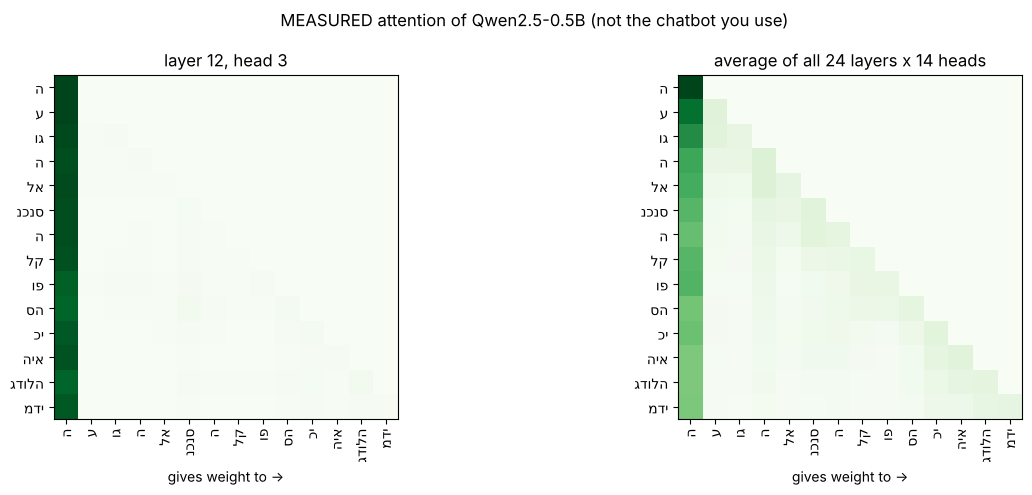

From 'גדולה', on average, the most weight goes to: 'ה' 47%, 'גדולה' 13%, 'היא' 12%, 'כי' 8%


In [2]:
import matplotlib.pyplot as plt


def rtl(word):
    # matplotlib draws text left to right; reversing a Hebrew word displays it correctly.
    return word[::-1]


def attention(sentence):
    """Attention weights of every layer and head: [layer, head, from, to], and the token pieces."""
    ids = tokenizer(sentence, return_tensors="pt").input_ids
    with torch.no_grad():
        out = model(ids, output_attentions=True)
    weights = torch.stack(out.attentions)[:, 0]
    return weights, [tokenizer.decode([i]) for i in ids[0]]


def show(sentence, word, layer=12, head=3):
    weights, pieces = attention(sentence)
    at = max(i for i, p in enumerate(pieces) if p.strip() == word)  # the piece that is the word
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, (title, mat) in zip(axes, [(f"layer {layer}, head {head}", weights[layer, head]),
                                       ("average of all 24 layers x 14 heads", weights.mean((0, 1)))]):
        ax.imshow(mat, cmap="Greens", vmin=0, vmax=1)
        ax.set_xticks(range(len(pieces)), [rtl(p.strip()) for p in pieces], rotation=90)
        ax.set_yticks(range(len(pieces)), [rtl(p.strip()) for p in pieces])
        ax.set_title(title)
        ax.set_xlabel("gives weight to ->")
    fig.suptitle("MEASURED attention of Qwen2.5-0.5B (not the chatbot you use)")
    plt.tight_layout()
    plt.show()
    row = weights.mean((0, 1))[at]
    top = row.topk(4)
    print(f"From '{word}', on average, the most weight goes to:",
          ", ".join(f"'{pieces[i].strip()}' {v:.0%}" for v, i in zip(top.values.tolist(), top.indices.tolist())))


show("העוגה לא נכנסה לקופסה כי היא גדולה מדי", "גדולה")

<div dir="rtl" style="text-align:right"><p>④ <b>מה רואים בפועל:</b> רוב המשקל הולך לטוקן <b>הראשון</b> במשפט – גם כשהוא לא קשור למשמעות. זה דפוס מוכר במודלי שפה (לפעמים קוראים לו «בור קשב»). שאר המשקל מתפזר בין כמה טוקנים קרובים. אין כאן חץ ברור מ«גדולה» אל «העוגה».</p>
<p><b>מה זה לא אומר:</b> שהמודל «לא מבין» או «מבין». ראשי הקשב עובדים יחד, לאורך 24 שכבות, והמידע עובר בדרכים שאי אפשר לקרוא בעין ממפה אחת. לכן ההמחשה באתר <b>פשוטה מהמציאות</b> – היא מסבירה את הרעיון, לא את המספרים.</p>
<blockquote>③ שנו את המשפט ל«…כי היא קטנה מדי» ואת המילה ל«קטנה», או נסו «שתיתי קפה עם חלב» עם המילה «עם». ④ האם התמונה משתנה הרבה?</blockquote></div>

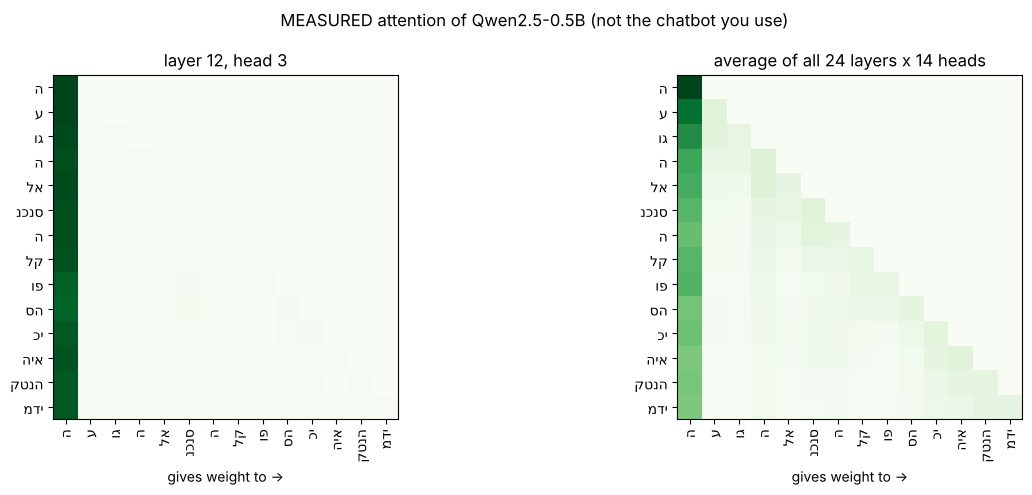

From 'קטנה', on average, the most weight goes to: 'ה' 49%, 'קטנה' 13%, 'היא' 12%, 'כי' 8%


In [3]:
show("העוגה לא נכנסה לקופסה כי היא קטנה מדי", "קטנה")  # <- ③ change the sentence and the word

<div dir="rtl" style="text-align:right"><p><b>סיימתם את המחברת של שלב C.</b> חזרו ללשונית של אתר הקורס וענו שם על שאלות השלב.</p></div>